# RQ1 - Effectiveness
ASR task (harvard) and intent matching task (commands). Baseline failures (clean input already wrong) are kept by default; their share is reported below and `EXCLUDE_BASELINE_FAILURES` in the first cell drops them.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

from results_loader import METHODS, load_results, load_intent_results, summary_table, intent_summary_table, tex_name, pretty, setup_latex_plots, PCT, ordered, method_color
from stats_utils import bootstrap_ci, wilson_ci, fmt_ci, comparison_table

setup_latex_plots()
EXCLUDE_BASELINE_FAILURES = True  # True: drop sentences whose clean input already fails (ASR) / maps to the wrong intent
ROOT = "../outputs/results"
asr = load_results(ROOT, dataset="harvard", asr_model="whisper-tiny")
asr_methods = [m for m in METHODS if asr[m]]
intent = load_intent_results(ROOT)
intent_methods = [m for m, r in intent.items() if r]
print("ASR:", {m: len(asr[m]) for m in asr_methods})
print("Intent:", {m: len(intent[m]) for m in intent_methods})

# baseline failures: clean input already fails (ASR: transcription != ground truth; intent: clean intent != reference)
base_asr = {m: np.mean([not r["original_passes"] for r in asr[m]]) for m in asr_methods}
base_intent = {m: np.mean([not r["intent"]["original_correct"] for r in intent[m]]) for m in intent_methods}
print("baseline failures ASR:", {m: f"{v:.1%}" for m, v in base_asr.items()})
print("baseline failures intent:", {m: f"{v:.1%}" for m, v in base_intent.items()})

if EXCLUDE_BASELINE_FAILURES:
    asr = {m: [r for r in rs if r["original_passes"]] for m, rs in asr.items()}
    intent = {m: [r for r in rs if r["intent"]["original_correct"]] for m, rs in intent.items()}
    print("excluded baseline failures; n:", {m: len(rs) for m, rs in asr.items()}, {m: len(rs) for m, rs in intent.items()})

ASR: {'GATAS': 100, 'Waveform': 100, 'SMACK': 100, 'ALIF': 100, 'PGD': 100, 'SMACK_targeted': 100}
Intent: {'GATAS': 100, 'Waveform': 100, 'SMACK_targeted': 100, 'ALIF': 100, 'PGD': 100, 'GATAS_llm': 100}
baseline failures ASR: {'GATAS': '29.0%', 'Waveform': '29.0%', 'SMACK': '28.0%', 'ALIF': '28.0%', 'PGD': '28.0%', 'SMACK_targeted': '28.0%'}
baseline failures intent: {'GATAS': '2.0%', 'Waveform': '2.0%', 'SMACK_targeted': '2.0%', 'ALIF': '2.0%', 'PGD': '2.0%', 'GATAS_llm': '2.0%'}
excluded baseline failures; n: {'GATAS': 71, 'Waveform': 71, 'SMACK': 72, 'ALIF': 72, 'PGD': 72, 'SMACK_targeted': 72} {'GATAS': 98, 'Waveform': 98, 'SMACK_targeted': 98, 'ALIF': 98, 'PGD': 98, 'GATAS_llm': 98}


## a) ASR task: effectiveness measures
Success = transcription differs from ground truth (Wilson 95% CI); quality measures are means with bootstrap 95% CI.

In [2]:
def effectiveness_table(records, extra=()):
    rows = {}
    for m, recs in records.items():
        if not recs:
            continue
        k, n = sum(r["success"] for r in recs), len(recs)
        row = {"n": n, "test case found %": fmt_ci(k / n, *wilson_ci(k, n), digits=1, scale=100)}
        for name, key in (("lexical (WER)", "wer"), ("semantic", "semantic"), ("spectrogram", "spectrogram"), ("UTMOS", "utmos")):
            v = [r[key] for r in recs]
            row[name] = fmt_ci(np.mean(v), *bootstrap_ci(v), digits=3)
        for name, fn in extra:
            row[name] = fn(recs)
        rows[m] = row
    return pd.DataFrame(rows).T

display(pretty(effectiveness_table({m: asr[m] for m in asr_methods})))
print(f"clean-audio UTMOS: {np.mean([r['utmos_original'] for r in asr[asr_methods[0]]]):.3f}")

,n,test case found %,lexical (WER),semantic,spectrogram,UTMOS
GATAS,71,"88.7 [79.3, 94.2]","0.191 [0.154, 0.232]","0.230 [0.191, 0.271]","0.068 [0.063, 0.074]","4.203 [4.115, 4.273]"
Waveform,71,"100.0 [94.9, 100.0]","1.180 [0.993, 1.549]","0.929 [0.917, 0.941]","0.160 [0.152, 0.167]","1.369 [1.343, 1.398]"
SMACK‡,72,"90.3 [81.3, 95.2]","1.202 [0.742, 1.771]","0.692 [0.611, 0.771]","0.190 [0.184, 0.196]","2.570 [2.348, 2.791]"
ALIF,72,"100.0 [94.9, 100.0]","1.244 [0.611, 2.113]","0.692 [0.652, 0.732]","0.192 [0.185, 0.201]","2.586 [2.482, 2.689]"
PGD,72,"100.0 [94.9, 100.0]","1.456 [1.108, 2.080]","0.896 [0.870, 0.920]","0.045 [0.044, 0.046]","3.937 [3.891, 3.982]"
SMACK,72,"69.4 [58.0, 78.9]","0.661 [0.325, 1.236]","0.352 [0.270, 0.439]","0.191 [0.186, 0.196]","3.193 [2.986, 3.401]"


clean-audio UTMOS: 4.392


## b) Intent matching task
*intent changed*: adversarial transcription classified as another intent than the clean one. *target hit*: changed to the target intent (untargeted methods: by chance).

In [3]:
def intent_extra(recs):
    n = len(recs)
    ch = sum(r["intent"]["changed"] for r in recs)
    hit = sum(r["intent"]["changed"] and r["intent"]["target_match"] for r in recs)
    return fmt_ci(ch / n, *wilson_ci(ch, n), digits=1, scale=100), fmt_ci(hit / n, *wilson_ci(hit, n), digits=1, scale=100)

tab = effectiveness_table({m: intent[m] for m in intent_methods})
tab.insert(1, "intent changed %", [intent_extra(intent[m])[0] for m in tab.index])
tab.insert(2, "target hit %", [intent_extra(intent[m])[1] for m in tab.index])
display(pretty(tab))
display(pretty(intent_summary_table({m: intent[m] for m in intent_methods}).round(3)))

,n,intent changed %,target hit %,test case found %,lexical (WER),semantic,spectrogram,UTMOS
GATAS,98,"20.4 [13.6, 29.4]","9.2 [4.9, 16.5]","99.0 [94.4, 99.8]","0.265 [0.231, 0.301]","0.246 [0.203, 0.293]","0.070 [0.065, 0.075]","4.185 [4.119, 4.247]"
Waveform,98,"82.7 [74.0, 88.9]","20.4 [13.6, 29.4]","96.9 [91.4, 99.0]","0.802 [0.738, 0.861]","0.717 [0.661, 0.769]","0.152 [0.143, 0.161]","1.397 [1.359, 1.443]"
SMACK,98,"28.6 [20.6, 38.2]","4.1 [1.6, 10.0]","77.6 [68.3, 84.7]","0.354 [0.296, 0.414]","0.272 [0.223, 0.324]","0.196 [0.188, 0.205]","3.452 [3.319, 3.587]"
ALIF,98,"66.3 [56.5, 74.9]","36.7 [27.9, 46.6]","99.0 [94.4, 99.8]","0.472 [0.423, 0.524]","0.475 [0.433, 0.519]","0.194 [0.185, 0.203]","2.584 [2.498, 2.665]"
PGD,98,"91.8 [84.7, 95.8]","6.1 [2.8, 12.7]","100.0 [96.2, 100.0]","1.421 [1.273, 1.602]","0.898 [0.877, 0.919]","0.046 [0.044, 0.049]","3.919 [3.872, 3.965]"
GATAS†,98,"84.7 [76.3, 90.5]","73.5 [64.0, 81.2]","96.9 [91.4, 99.0]","0.494 [0.432, 0.561]","0.477 [0.431, 0.523]","0.105 [0.099, 0.111]","4.154 [4.102, 4.202]"


,intent changed %,target intent %,lexical (WER),semantic,spectrogram,UTMOS
GATAS,20.408,45.000,0.265,0.246,0.070,4.185
Waveform,82.653,24.691,0.802,0.717,0.152,1.397
SMACK,28.571,14.286,0.354,0.272,0.196,3.452
ALIF,66.327,55.385,0.472,0.475,0.194,2.584
PGD,91.837,6.667,1.421,0.898,0.046,3.919
GATAS†,84.694,86.747,0.494,0.477,0.105,4.154


### Effectiveness vs. naturalness
Mean with 95% CI (Wilson for rates, bootstrap for UTMOS). Top right is best: more test cases found, closer to natural speech (clean-audio UTMOS dashed).

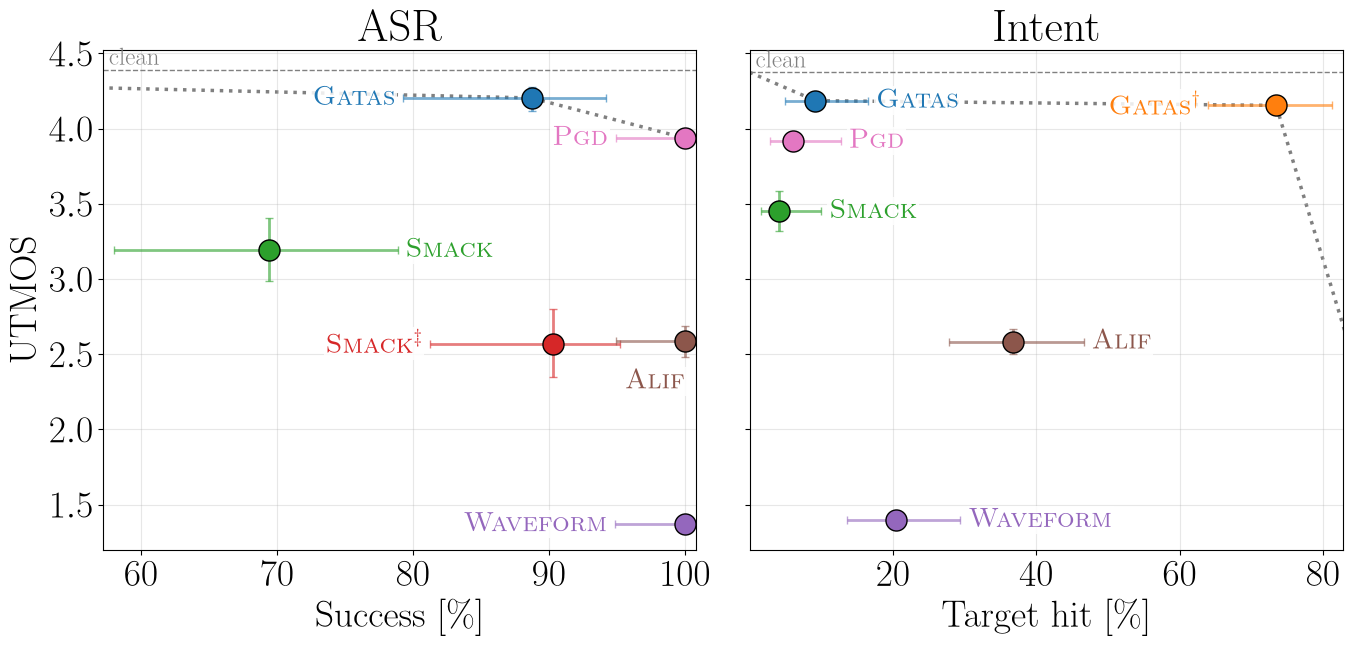

In [4]:
def tradeoff_panel(ax, records, success_fn, ylabel, title, x_key="utmos", clean_x=None, first=True):
    pts = []
    for m, recs in records.items():
        n = len(recs)
        k = sum(success_fn(r) for r in recs)
        y, (ylo, yhi) = k / n, wilson_ci(k, n)
        xs = [r[x_key] for r in recs]
        x, (xlo, xhi) = np.mean(xs), bootstrap_ci(xs)
        ax.errorbar(100 * y, x, xerr=[[100 * max(y - ylo, 0)], [100 * max(yhi - y, 0)]], yerr=[[max(x - xlo, 0)], [max(xhi - x, 0)]],
                    fmt="none", ecolor=method_color(m), alpha=0.6, lw=2, capsize=3, zorder=2)
        ax.scatter(100 * y, x, s=230, color=method_color(m), edgecolor="black", zorder=3)
        pts.append((m, 100 * y, x, method_color(m), 100 * yhi, 100 * ylo))
    ax.set_xlabel(ylabel + " [" + PCT + "]"); ax.set_ylabel("UTMOS" if first else ""); ax.set_title(title)
    ax.grid(alpha=0.3)

    # limits: data range plus a 2 % margin on both sides (rates never exceed 100 %); fixed so the front line cannot widen them
    lo_min, hi_max = min(p[5] for p in pts), max(p[4] for p in pts)
    margin = 0.02 * (hi_max - lo_min)
    ax.set_xlim(lo_min - margin, hi_max + margin)
    ax.set_xticks([t for t in ax.get_xticks() if 0 <= t <= 100 and lo_min - margin <= t <= hi_max + margin])
    ax.set_xlim(lo_min - margin, hi_max + margin)
    if clean_x is not None:
        ax.set_ylim(top=clean_x + 0.15)
    ax.autoscale(False)
    x0, x1 = ax.get_xlim()

    # clean-audio reference (dashed) and Pareto front (dotted) over the means: starts at (0, clean), ends horizontally at 100 %
    if clean_x is not None:
        ax.axhline(clean_x, color="gray", ls="--", lw=1)
        ax.text(x0 + 0.01 * (x1 - x0), clean_x, "clean", va="bottom", color="gray", fontsize=18)
    # anchors: no attack (0 % success, clean UTMOS) and a trivial 100 % success with UTMOS 0; they stay on the front unless dominated
    anchors = ([("clean", 0.0, clean_x)] if clean_x is not None else []) + [("max", 100.0, 0.0)]
    cand = [(p[0], p[1], p[2]) for p in pts] + anchors
    eps = 1e-9
    front = sorted([c for c in cand if not any(o is not c and o[1] >= c[1] - eps and o[2] >= c[2] - eps and (o[1] > c[1] + eps or o[2] > c[2] + eps) for o in cand)], key=lambda c: c[1])
    ax.plot([c[1] for c in front], [c[2] for c in front], color="gray", ls=":", lw=2.5, zorder=1)

    # labels beside the horizontal range (right, else left, else below/above), avoiding other ranges and labels
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    tr = ax.transData
    axbox = ax.get_window_extent()
    pad = 6
    obstacles = []
    for m, px, py, c, hi, lo in pts:
        (xa, ya), (xb, _) = tr.transform((lo, py)), tr.transform((hi, py))
        obstacles.append((xa - 14, ya - 14, xb + 14, ya + 14))
    def overlaps(r, o):
        return not (r[2] < o[0] or r[0] > o[2] or r[3] < o[1] or r[1] > o[3])
    for idx, (m, px, py, c, hi, lo) in enumerate(pts):
        others = obstacles[:idx] + obstacles[idx + 1:]
        (xl, yp), (xh, _) = tr.transform((lo, py)), tr.transform((hi, py))
        options = [("left", xh + 8, yp, "left", "center"), ("right", xl - 8, yp, "right", "center"),
                   ("below", xh, yp - 24, "right", "center"), ("above", xh, yp + 24, "right", "center"),
                   ("below2", xh, yp - 40, "right", "center"), ("above2", xh, yp + 40, "right", "center")]
        for name, xx, yy, ha, va in options:
            t = ax.annotate(tex_name(m), tr.inverted().transform((xx, yy)), ha=ha, va=va, fontsize=20, color=c, zorder=4,
                            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
            bb = t.get_window_extent(renderer)
            r = (bb.x0 - pad, bb.y0 - pad, bb.x1 + pad, bb.y1 + pad)
            inside = r[0] >= axbox.x0 and r[2] <= axbox.x1 and r[1] >= axbox.y0 and r[3] <= axbox.y1
            if inside and not any(overlaps(r, o) for o in others):
                obstacles.append(r)
                break
            t.remove()
        else:  # nothing free: fall back to the right
            ax.annotate(tex_name(m), (hi, py), textcoords="offset points", xytext=(8, 0), ha="left", va="center", fontsize=20, color=c)

with plt.rc_context({"font.size": 27}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharey=True, gridspec_kw={"wspace": 0.09})
    tradeoff_panel(axes[0], {m: asr[m] for m in asr_methods}, lambda r: r["success"], "Success", "ASR",
                   clean_x=np.mean([r["utmos_original"] for r in asr[asr_methods[0]]]))
    tradeoff_panel(axes[1], {m: intent[m] for m in intent_methods},
                   lambda r: r["intent"]["changed"] and r["intent"]["target_match"], "Target hit", "Intent",
                   clean_x=np.mean([r["utmos_original"] for r in intent[intent_methods[0]]]), first=False)
    plt.savefig("_figures/tradeoff_methods.pdf", bbox_inches="tight")
    plt.savefig("_figures/tradeoff_methods.png", dpi=120, bbox_inches="tight")

## Spectrogram comparison
Per method: original, final candidate, difference (candidate - original) for the same sentence.

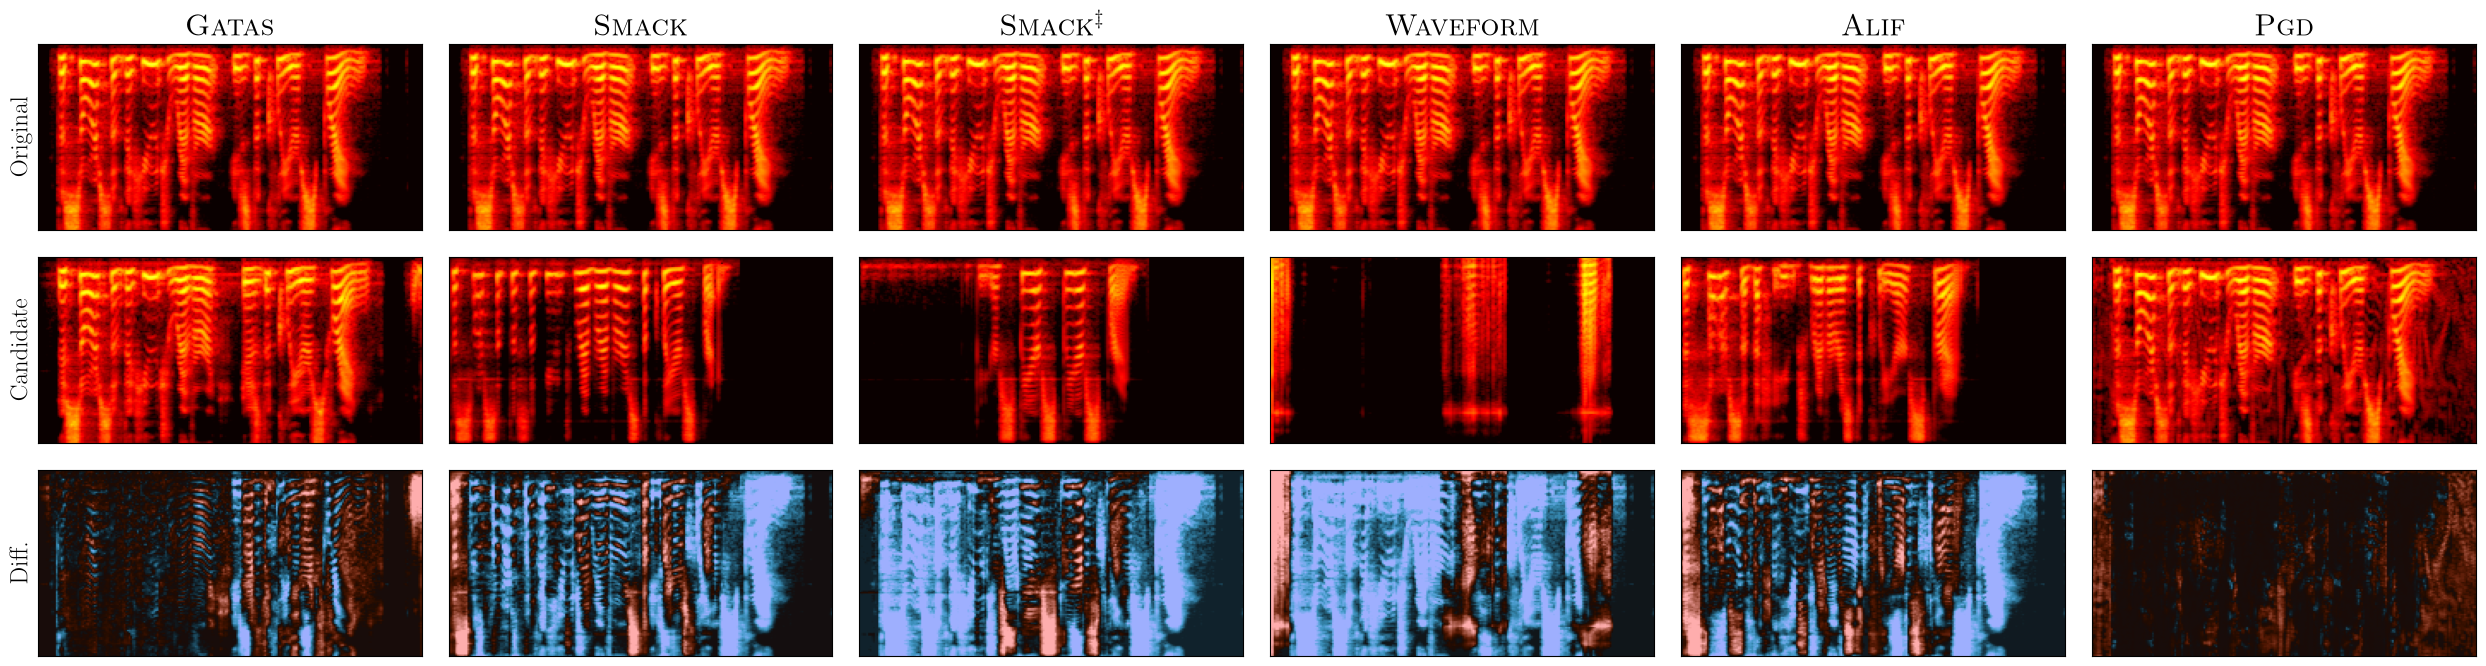

In [5]:
def to_spectrogram(file):
    y, sr = librosa.load(file, sr=None)
    return librosa.power_to_db(np.abs(librosa.feature.melspectrogram(y=y, sr=sr, n_fft=1024, hop_length=256, n_mels=128)))

def fit(spec, T):
    if spec.shape[1] < T:
        spec = np.pad(spec, ((0, 0), (0, T - spec.shape[1])), constant_values=spec.min())
    return spec[:, :T]

def spectrogram_grid(records, sentence_id, tag):
    ms = ordered(m for m, rs in records.items() if any(r["sentence_id"] == sentence_id for r in rs))
    fig, axes = plt.subplots(3, len(ms), figsize=(4.2 * len(ms), 7), squeeze=False)
    for j, m in enumerate(ms):
        r = next(r for r in records[m] if r["sentence_id"] == sentence_id)
        g, b = to_spectrogram(r["gt_wav"]), to_spectrogram(r["adv_wav"])
        T = max(g.shape[1], b.shape[1]); g, b = fit(g, T), fit(b, T)
        for i, (img, title) in enumerate(zip([g, b, b - g], ["Original", "Candidate", "Diff."])):
            ax = axes[i, j]
            if i < 2:
                ax.imshow(img, cmap="hot", vmin=-60, vmax=40, aspect="auto")
            else:
                ax.imshow(img, cmap="berlin", norm=TwoSlopeNorm(vmin=-40, vcenter=0, vmax=40), aspect="auto")
            ax.set_xticks([]); ax.set_yticks([])
            if j == 0: ax.set_ylabel(title)
            if i == 0: ax.set_title(tex_name(m))
    plt.tight_layout()
    plt.savefig(f"_figures/spec_{tag}_{sentence_id:03d}.jpg", dpi=200, bbox_inches="tight")
    plt.show()

spectrogram_grid(asr, 13, "asr")

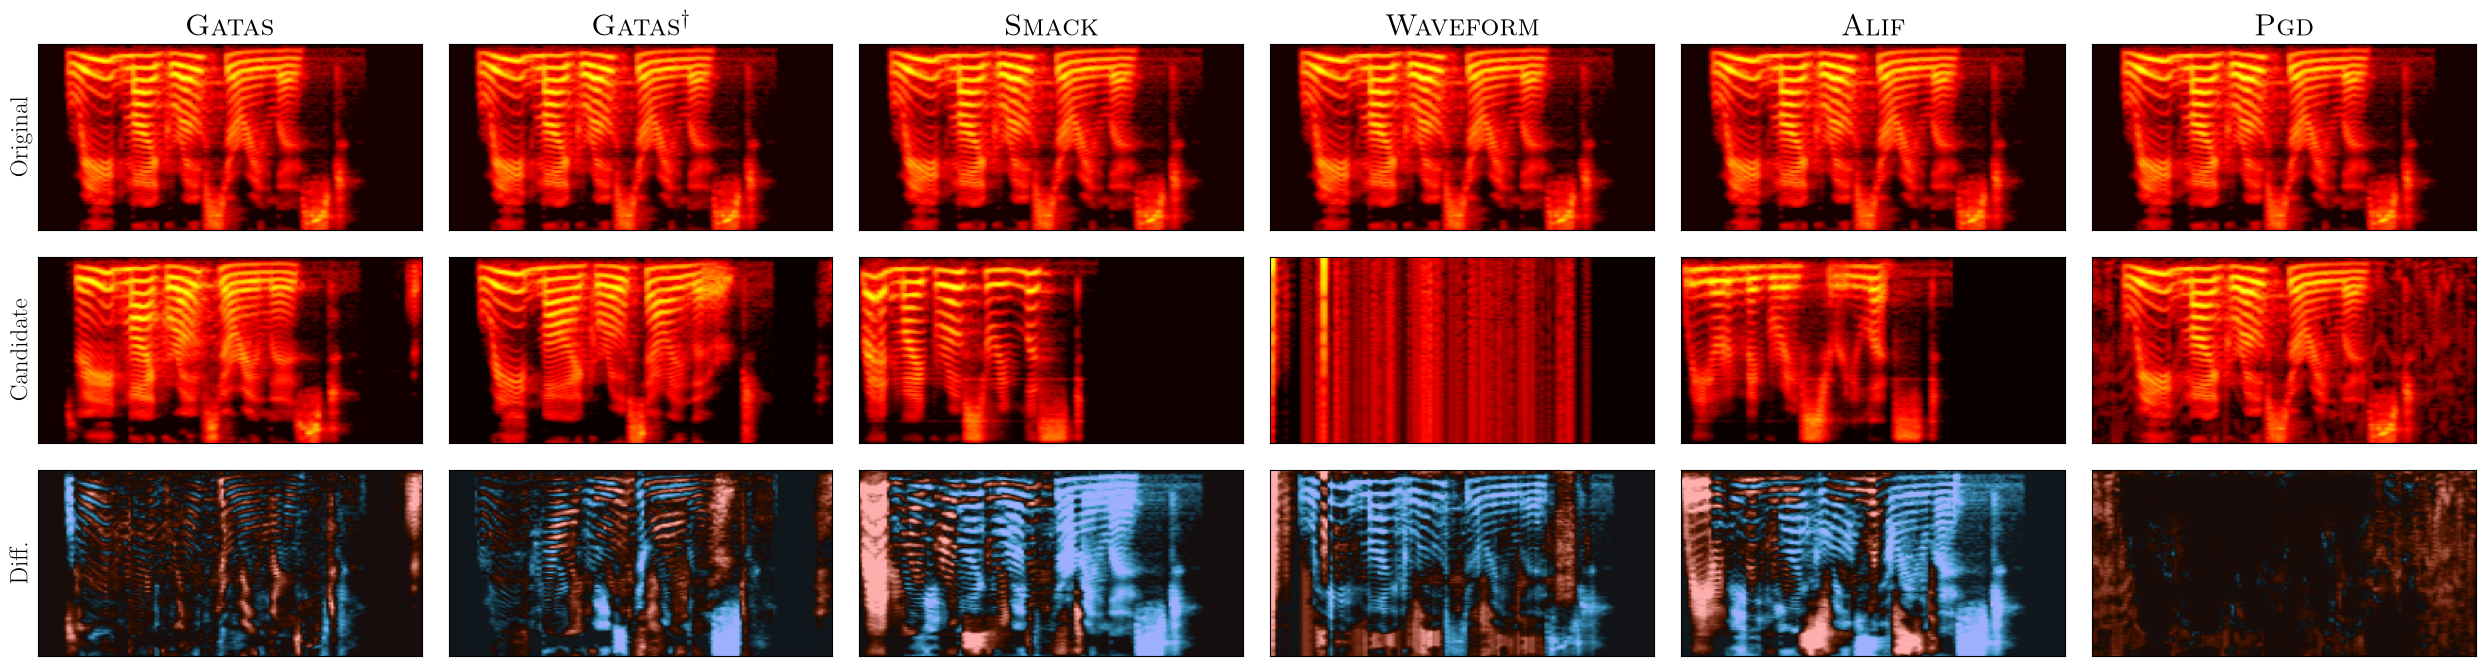

In [6]:
common = sorted(set.intersection(*(set(r["sentence_id"] for r in intent[m]) for m in intent_methods)))
spectrogram_grid(intent, common[0], "intent")

## Statistical analysis
GATAS vs. every other method, paired by sentence. Binary measures: exact McNemar, difference of proportions (bootstrap CI), odds ratio of discordant pairs. Continuous measures: Wilcoxon signed-rank, paired Cohen's d_z with bootstrap CI. Two-sided, Holm-corrected per measure.

In [7]:
asr_metrics = {
    "test case found": (lambda r: float(r["success"]), True, "two-sided"),
    "WER": (lambda r: r["wer"], False, "two-sided"),
    "semantic": (lambda r: r["semantic"], False, "two-sided"),
    "spectrogram": (lambda r: r["spectrogram"], False, "two-sided"),
    "UTMOS": (lambda r: r["utmos"], False, "two-sided"),
}
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 60)
print("ASR task")
display(pretty(comparison_table({m: asr[m] for m in asr_methods}, "GATAS", asr_metrics)))

ASR task


,metric,vs,n,GATAS,other,diff [95% CI],p,effect,p (Holm)
0,test case found,Waveform,70,0.885714,1.000000,"-0.114 [-0.186, -0.043]",7.812500e-03,odds ratio=0.00,3.906250e-02
1,test case found,SMACK‡,71,0.887324,0.901408,"-0.014 [-0.127, 0.099]",1.000000e+00,odds ratio=0.88,1.000000e+00
2,test case found,ALIF,71,0.887324,1.000000,"-0.113 [-0.197, -0.042]",7.812500e-03,odds ratio=0.00,3.906250e-02
3,test case found,PGD,71,0.887324,1.000000,"-0.113 [-0.197, -0.042]",7.812500e-03,odds ratio=0.00,3.906250e-02
4,test case found,SMACK,71,0.887324,0.690141,"0.197 [0.056, 0.338]",1.612480e-02,odds ratio=2.75,3.906250e-02
5,WER,Waveform,70,0.189836,1.182143,"-0.992 [-1.389, -0.774]",4.686043e-13,"d_z=-0.63 [-7.13, -0.51]",1.874417e-12
6,WER,SMACK‡,71,0.190683,1.204907,"-1.014 [-1.584, -0.549]",5.630354e-11,"d_z=-0.44 [-1.21, -0.40]",1.126071e-10
7,WER,ALIF,71,0.190683,1.252951,"-1.062 [-1.942, -0.422]",4.790188e-12,"d_z=-0.32 [-1.51, -0.28]",1.437056e-11
8,WER,PGD,71,0.190683,1.453823,"-1.263 [-1.919, -0.904]",3.500046e-13,"d_z=-0.50 [-3.32, -0.42]",1.750023e-12
9,WER,SMACK,71,0.190683,0.668159,"-0.477 [-1.097, -0.128]",4.830163e-04,"d_z=-0.21 [-0.64, -0.17]",4.830163e-04


In [8]:
intent_metrics = {
    "intent changed": (lambda r: float(r["intent"]["changed"]), True, "two-sided"),
    "target hit": (lambda r: float(r["intent"]["changed"] and r["intent"]["target_match"]), True, "two-sided"),
    **{k: v for k, v in asr_metrics.items() if k != "test case found"},
}
print("Intent matching task")
display(pretty(comparison_table({m: intent[m] for m in intent_methods}, "GATAS", intent_metrics)))

Intent matching task


,metric,vs,n,GATAS,other,diff [95% CI],p,effect,p (Holm)
0,intent changed,Waveform,98,0.204082,0.826531,"-0.622 [-0.724, -0.520]",1.163349e-16,odds ratio=0.03,3.490047e-16
1,intent changed,SMACK,98,0.204082,0.285714,"-0.082 [-0.194, 0.031]",2.294810e-01,odds ratio=0.62,2.294810e-01
2,intent changed,ALIF,98,0.204082,0.663265,"-0.459 [-0.571, -0.347]",7.053980e-11,odds ratio=0.08,1.410796e-10
3,intent changed,PGD,98,0.204082,0.918367,"-0.714 [-0.806, -0.612]",2.939204e-19,odds ratio=0.03,1.175682e-18
4,intent changed,GATAS†,98,0.204082,0.846939,"-0.643 [-0.735, -0.551]",2.168404e-19,odds ratio=0.00,1.084202e-18
5,target hit,Waveform,98,0.091837,0.204082,"-0.112 [-0.184, -0.041]",7.385254e-03,odds ratio=0.15,2.215576e-02
6,target hit,SMACK,98,0.091837,0.040816,"0.051 [0.000, 0.102]",1.250000e-01,odds ratio=6.00,2.500000e-01
7,target hit,ALIF,98,0.091837,0.367347,"-0.276 [-0.378, -0.173]",1.401175e-06,odds ratio=0.10,5.604699e-06
8,target hit,PGD,98,0.091837,0.061224,"0.031 [-0.031, 0.092]",5.078125e-01,odds ratio=2.00,5.078125e-01
9,target hit,GATAS†,98,0.091837,0.734694,"-0.643 [-0.735, -0.541]",2.168404e-19,odds ratio=0.00,1.084202e-18
